# Personal Kpop Timeline

Draws my K-pop bias timeline from three CSV files in this folder: `groups.csv`, `biases.csv` and `songs.csv`.

Run all cells from top to bottom (Kernel > Restart & Run All).

## 1. Imports
pandas reads the CSV files, matplotlib draws the chart.

In [11]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors, font_manager

_ = plt.ioff()   # draw the chart quietly and only show it at the very end

## 2. Settings
Change these by hand. NOW is the last month on the chart.

In [21]:
NOW = "2026-11"
FIRST_YEAR = 2018
LAST_YEAR = 2026

TITLE = "PERSONAL KPOP TIMELINE"
SUBTITLE = "Nine acts since 2018, and TXT is the one I've stuck with"
AUTHOR = "Alex Anakondak"
DATE_LINE = "November 2026"

BLACK = "#111111"
GREY_TEXT = "#6a6a6a"
GRID_LINE = "#f0f0f0"

# Use the first font from this list that is installed on the computer.
# Inter looks closest to the design; Segoe UI and Arial come with Windows.
installed_fonts = [f.name for f in font_manager.fontManager.ttflist]
for font in ["Inter", "Segoe UI", "Arial"]:
    if font in installed_fonts:
        plt.rcParams["font.family"] = font
        break

## 3. Helper functions
Small tools used later. A date like "2024-04" is turned into a number like 2024.25 so matplotlib knows where to put it on the time axis.

In [13]:
def date_to_number(date):
    """Turn '2024-04' into 2024.25. The word 'now' means the NOW month."""
    if date == "now":
        date = NOW
    year = int(date[:4])
    month = int(date[5:7])
    return year + (month - 1) / 12


def month_middle(date):
    """Same as date_to_number, but in the middle of the month (used for song dots)."""
    return date_to_number(date) + 1 / 24


def count_months(start, end):
    """How many months a bias lasted, e.g. '2020-06' to '2024-03' is 45 months."""
    still_going = (end == "now")
    if still_going:
        end = NOW
    months = (int(end[:4]) - int(start[:4])) * 12 + (int(end[5:7]) - int(start[5:7]))
    if still_going:
        months = months + 1      # count this month too
    return months


def months_to_text(months):
    """Turn 45 into '3y 9m'."""
    years = months // 12
    left_over = months % 12
    text = ""
    if years > 0:
        text = str(years) + "y"
    if left_over > 0:
        text = text + " " + str(left_over) + "m"
    return text.strip()


def darker(colour):
    """A darker version of a colour, so small coloured text is easy to read."""
    red, green, blue = colors.to_rgb(colour)
    return (red * 0.62, green * 0.62, blue * 0.62)

## 4. Load the data
Each CSV becomes a table (a pandas DataFrame). biases.csv uses | when two members were my bias at the same time.

In [14]:
groups = pd.read_csv("groups.csv")
biases = pd.read_csv("biases.csv")
songs = pd.read_csv("songs.csv").fillna("")

# Give every group a row number: BTS = 0 (top), Stray Kids = 1, and so on.
row_number = {}
for i, name in enumerate(groups["group"]):
    row_number[name] = i

## 5. Work out the numbers for the top boxes
Number of acts, number of biases, the longest bias and the current bias.

In [15]:
biases["months"] = [count_months(s, e) for s, e in zip(biases["start"], biases["end"])]

all_biases = set()
current_biases = []
longest_name, longest_months = "", 0

for _, row in biases.iterrows():
    names = row["members"].split("|")
    for name in names:
        all_biases.add(name)
        if row["end"] == "now":
            current_biases.append(name)
    if len(names) == 1 and row["months"] > longest_months:
        longest_name = names[0]
        longest_months = row["months"]

boxes = [
    (str(len(groups)), "GROUPS AND SOLOISTS"),
    (str(len(all_biases)), "BIASES"),
    (months_to_text(longest_months), "LONGEST: " + longest_name.upper()),
    (str(len(current_biases)), "CURRENT BIAS: " + ", ".join(current_biases).upper()),
]

## 6. Set up the page
A 1920 x 1080 white page with the title, subtitle and the four boxes. Positions on the page go from 0 (left/bottom) to 1 (right/top).

In [16]:
fig = plt.figure(figsize=(19.2, 10.8), dpi=100)

# gold bar above the title
fig.add_artist(plt.Rectangle((0.05, 0.935), 0.0375, 0.0075, color="#E8A317", transform=fig.transFigure))
fig.text(0.05, 0.885, TITLE, fontsize=44, fontweight="heavy", color=BLACK, va="center")
fig.text(0.05, 0.835, SUBTITLE, fontsize=15, color=GREY_TEXT, va="center")

for i, (number, label) in enumerate(boxes):
    left = 0.532 + i * 0.106
    fig.add_artist(plt.Line2D([left, left + 0.099], [0.944, 0.944], color=BLACK, lw=3,
                              transform=fig.transFigure))
    fig.text(left, 0.905, number, fontsize=31, fontweight="heavy", color=BLACK, va="center")
    fig.text(left, 0.87, label, fontsize=9.5, fontweight="semibold", color=GREY_TEXT, va="center")

## 7. Set up the chart area
x = time in years, y = row number (flipped so BTS is at the top).

In [17]:
ax = fig.add_axes([0.155, 0.115, 0.795, 0.655])
ax.set_xlim(FIRST_YEAR, LAST_YEAR + 1)
ax.set_ylim(len(groups) - 0.35, -0.75)

# hide the box around the chart and the y axis
for side in ax.spines.values():
    side.set_visible(False)
ax.set_yticks([])

# year labels in the middle of each year, light lines at the start of each year
years = list(range(FIRST_YEAR, LAST_YEAR + 1))
ax.set_xticks([y + 0.5 for y in years])
ax.set_xticklabels([str(y) for y in years], fontsize=11, color=GREY_TEXT)
ax.tick_params(axis="x", length=0, pad=10)
for y in range(FIRST_YEAR, LAST_YEAR + 2):
    ax.axvline(y, color=GRID_LINE, lw=1, zorder=0)

# dashed "now" line
now_x = date_to_number(NOW) + 1 / 12
ax.axvline(now_x, color="#bbbbbb", lw=1.2, linestyle="--", zorder=1)
ax.text(now_x + 0.03, len(groups) - 0.35, "NOW", fontsize=9.5, color=GREY_TEXT,
        fontweight="semibold", va="top")

# group names and the small line under them, on the left
for _, g in groups.iterrows():
    y = row_number[g["group"]]
    ax.text(-0.132, y - 0.05, g["group"], transform=ax.get_yaxis_transform(),
            fontsize=15, fontweight="heavy", color=BLACK, va="center")
    ax.text(-0.132, y + 0.22, g["subtitle"], transform=ax.get_yaxis_transform(),
            fontsize=9, color=GREY_TEXT, va="center")

# Matplotlib only knows how wide a piece of text is after drawing it.
# This measures a text's width in years, so we can place things next to it.
renderer = fig.canvas.get_renderer()

def width_in_years(text):
    box = text.get_window_extent(renderer=renderer)
    left = ax.transData.inverted().transform((box.x0, 0))[0]
    right = ax.transData.inverted().transform((box.x1, 0))[0]
    return right - left

## 8. Draw the bias bars
One thick line per bias, with the member's name and how long it lasted underneath.

In [18]:
BAR_THICKNESS = 7

for _, b in biases.iterrows():
    y = row_number[b["group"]]
    start = date_to_number(b["start"])
    end = date_to_number(b["end"])
    if b["end"] == "now":
        end = end + 1 / 12             # draw to the end of this month

    names = b["members"].split("|")
    bar_colours = b["colours"].split("|")

    if len(names) == 1:
        ax.plot([start, end], [y, y], color=bar_colours[0], lw=BAR_THICKNESS, solid_capstyle="butt", zorder=2)
    else:
        # two biases at the same time: short stripes that swap colour
        x = start
        stripe = 0
        while x < end:
            ax.plot([x, min(x + 0.07, end)], [y, y], color=bar_colours[stripe % 2],
                    lw=BAR_THICKNESS, solid_capstyle="butt", zorder=2)
            x = x + 0.07
            stripe = stripe + 1

    # names under the bar (stacked if there are two), duration after the last one
    for i, name in enumerate(names):
        name_y = y + 0.2 + i * 0.2
        name_text = ax.text(start, name_y, name, fontsize=10, fontweight="semibold",
                            color=darker(bar_colours[i]), va="center")
        if i == len(names) - 1:
            ax.text(start + width_in_years(name_text) + 0.03, name_y,
                    months_to_text(b["months"]), fontsize=10, color="#666666", va="center")

## 9. Draw the song points
A dot for each song, with its name above. If two names would bump into each other, the second one moves right, and a thin grey line joins each name to its dot.

In [19]:
LABEL_HEIGHT = 0.3      # how far above the bar the names sit
GAP = 0.06              # space between two names

for group_name, group_songs in songs.groupby("group", sort=False):
    y = row_number[group_name]
    group_songs = group_songs.sort_values("date")

    # step 1: write every name above its dot and measure it
    labels = []
    for _, s in group_songs.iterrows():
        dot_x = month_middle(s["date"])
        text = ax.text(dot_x, y - LABEL_HEIGHT, s["label"].replace("|", "\n"),
                       fontsize=9.5, color="#444444", ha="center", va="bottom")
        labels.append({"dot_x": dot_x, "text": text, "width": width_in_years(text), "song": s})

    # step 2: going left to right, push a name right if it overlaps the one before
    right_edge_of_last = -9999
    for lab in labels:
        left = lab["dot_x"] - lab["width"] / 2
        if left < right_edge_of_last + GAP:
            left = right_edge_of_last + GAP
        lab["left"] = left
        right_edge_of_last = left + lab["width"]

    # step 3: going right to left, pull names back if they run off the chart
    limit = LAST_YEAR + 1.15
    for lab in reversed(labels):
        if lab["left"] + lab["width"] > limit:
            lab["left"] = limit - lab["width"]
        limit = lab["left"] - GAP

    # step 4: move each name to its final spot, draw the grey line and the dot
    names_shown = []
    for lab in labels:
        middle = lab["left"] + lab["width"] / 2
        lab["text"].set_x(middle)
        ax.plot([lab["dot_x"], middle], [y - 0.07, y - LABEL_HEIGHT + 0.02],
                color="#c4c4c4", lw=0.8, zorder=1)

        s = lab["song"]
        if s["dot_member"] == "":
            # normal dot: white with a black ring
            ax.scatter(lab["dot_x"], y, s=55, facecolor="white", edgecolor=BLACK, linewidth=2, zorder=4)
        else:
            # coloured dot for a bias with no bar (e.g. Jungkook's solos)
            ax.scatter(lab["dot_x"], y, s=55, color=s["dot_colour"], zorder=4)
            if s["dot_member"] not in names_shown:
                ax.text(lab["dot_x"] - 0.04, y + 0.2, s["dot_member"], fontsize=10,
                        fontweight="semibold", color=darker(s["dot_colour"]), va="center")
                names_shown.append(s["dot_member"])

## 10. Footer and save
Source and note at the bottom, then save two sizes of PNG.

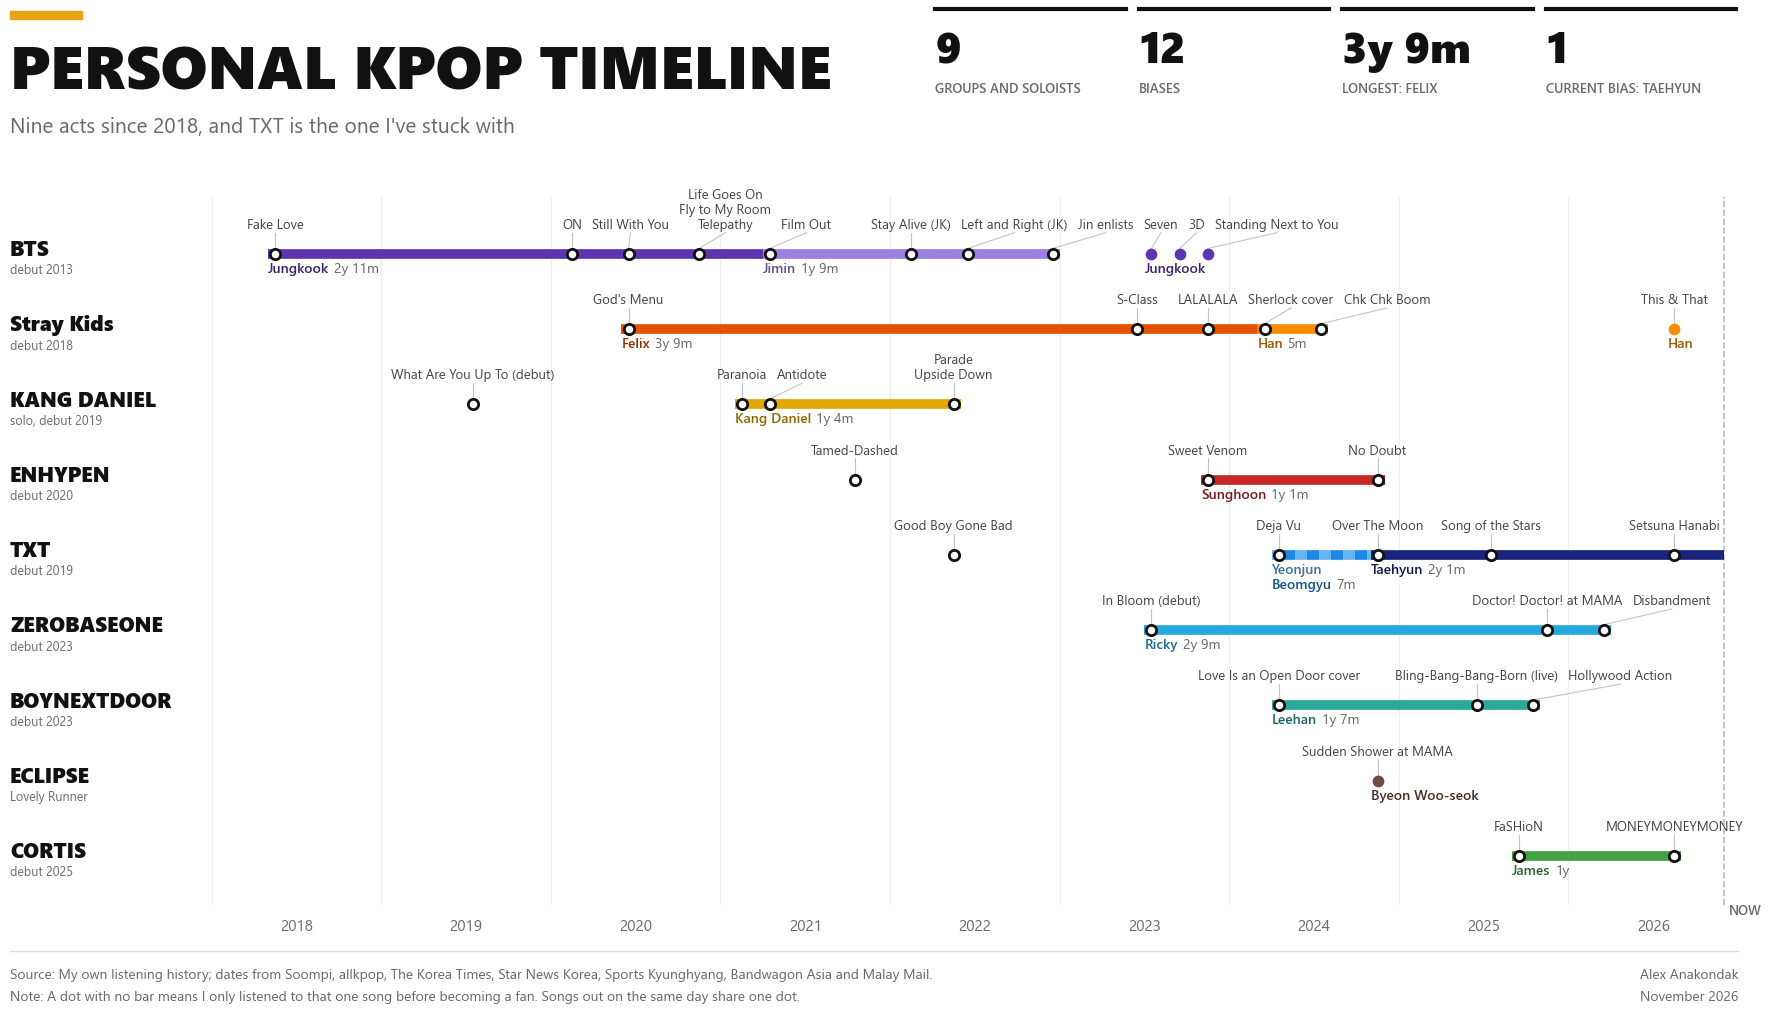

In [20]:
fig.add_artist(plt.Line2D([0.05, 0.95], [0.072, 0.072], color="#dddddd", lw=1, transform=fig.transFigure))
fig.text(0.05, 0.05, SOURCE, fontsize=10, color="#666666", va="center")
fig.text(0.05, 0.03, NOTE, fontsize=10, color="#666666", va="center")
fig.text(0.95, 0.05, AUTHOR, fontsize=10, color="#666666", va="center", ha="right")
fig.text(0.95, 0.03, DATE_LINE, fontsize=10, color="#666666", va="center", ha="right")

fig.savefig("personal_kpop_timeline.png", dpi=100)      # 1920 x 1080
fig.savefig("personal_kpop_timeline_4k.png", dpi=200)   # 3840 x 2160 for Canva
plt.show()